In [1]:
### standard libraries
import time
import numpy as np
import matplotlib.pyplot as plt

### other libraries
import finufft

### my modules
from fast_volume_align_ot import utils, plots, transforms, distances

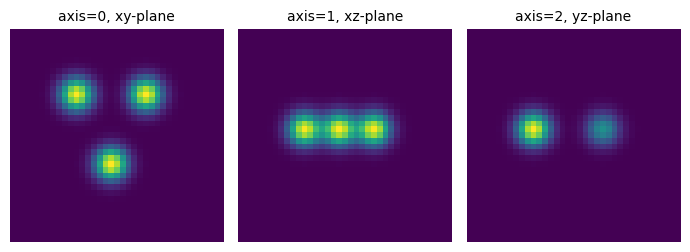

In [2]:
### generate initial volume
L = 37
sigma = 2
f = utils.generate_3d_triangle_gaussian_shape(L, sigma)

plots.orthogonal_2D_projection_plot(f)

In [3]:
t = time.time()
F = transforms.compute_projection_tensor_from_voxel_array(f)
# F_cdf = transforms.pdf_tensor_to_cdf_tensor(F)
# U = transforms.cdf_tensor_to_icdf_tensor(F_cdf)
print('transform time: ', time.time() - t)

transform time:  0.044092655181884766


In [4]:
thetas = np.linspace(0, 2*np.pi, L, endpoint=False)
print(np.round(np.rad2deg(thetas), 1))

[  0.    9.7  19.5  29.2  38.9  48.6  58.4  68.1  77.8  87.6  97.3 107.
 116.8 126.5 136.2 145.9 155.7 165.4 175.1 184.9 194.6 204.3 214.1 223.8
 233.5 243.2 253.  262.7 272.4 282.2 291.9 301.6 311.4 321.1 330.8 340.5
 350.3]


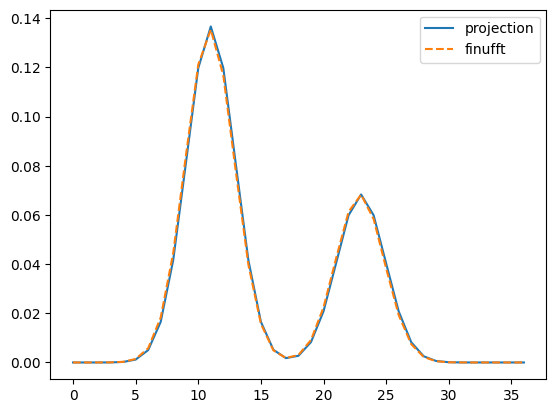

In [72]:
theta_idx, phi_idx = 9, 9
ax1, ax2 = 2, 0

plt.plot(np.sum(f, axis=(ax1, ax2)), label='projection')
plt.plot(F[phi_idx, :, theta_idx], '--', label='finufft')
plt.legend()
plt.show()